## ML Lab
##### Name: Manas Nair
##### Section-Batch: C-C3
##### Roll No: 39

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


In [3]:
df = pd.read_csv("diabetes(6).csv")


In [4]:
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [5]:
print(df.tail())

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
763                     0.171   63        0  
764                     0.340   27        0  
765                     0.245   30        0  
766                     0.349   47        1  
767                     0.315   23        0  


In [6]:
print("Shape:", df.shape)

Shape: (768, 9)


In [7]:
print("Columns:", df.columns)

Columns: Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [8]:
print("Missing values:")

Missing values:


In [9]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


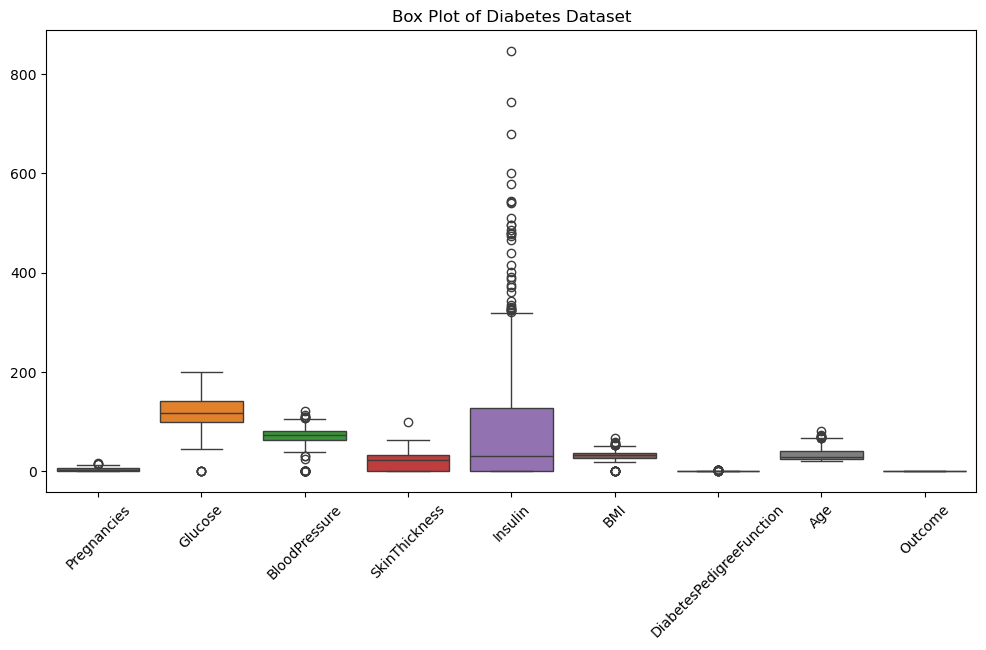

In [19]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df)

plt.title("Box Plot of Diabetes Dataset")
plt.xticks(rotation=45)
plt.show()

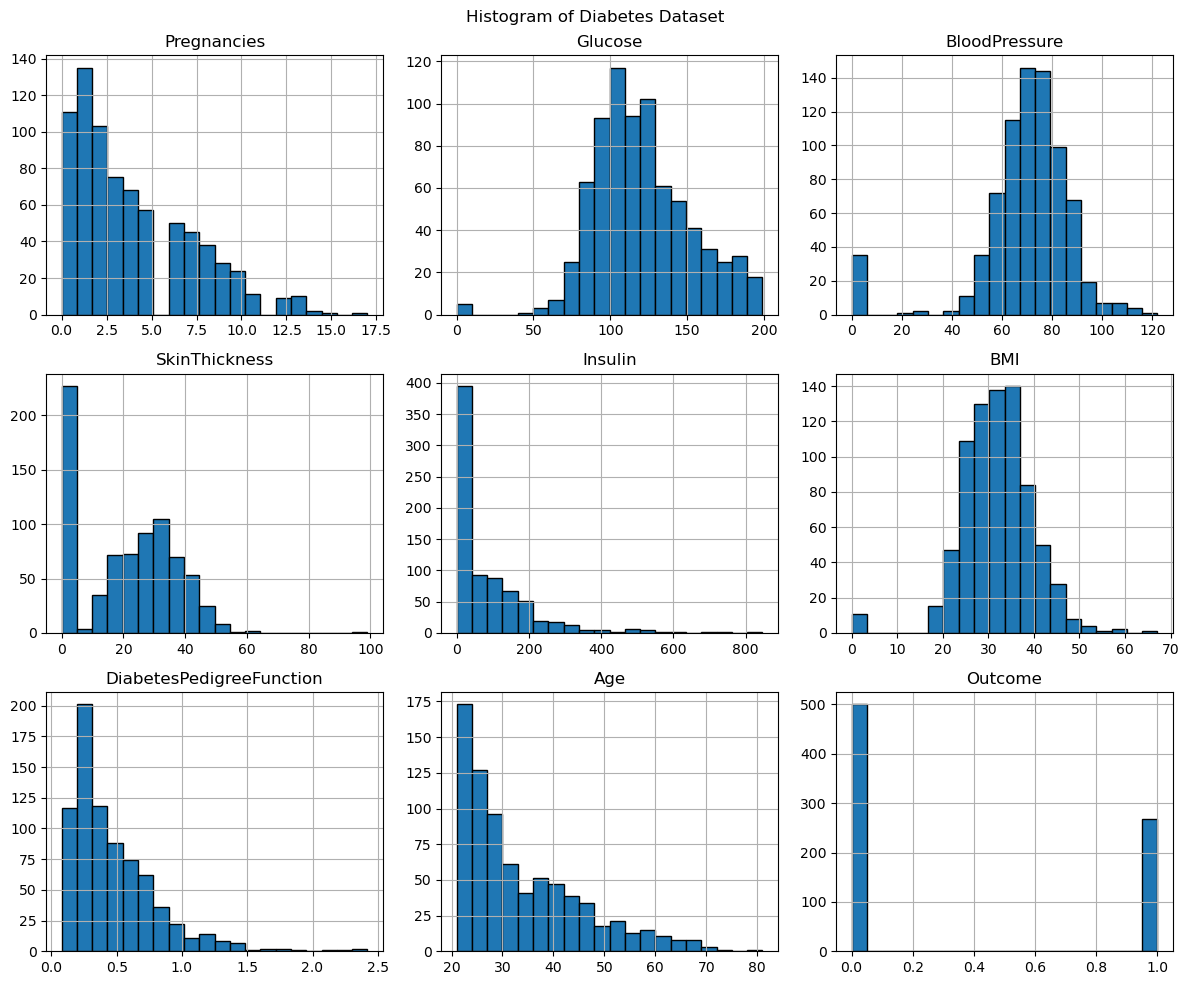

In [20]:
df.hist(figsize=(12, 10), bins=20, edgecolor="black")

plt.suptitle("Histogram of Diabetes Dataset")
plt.tight_layout()
plt.show()

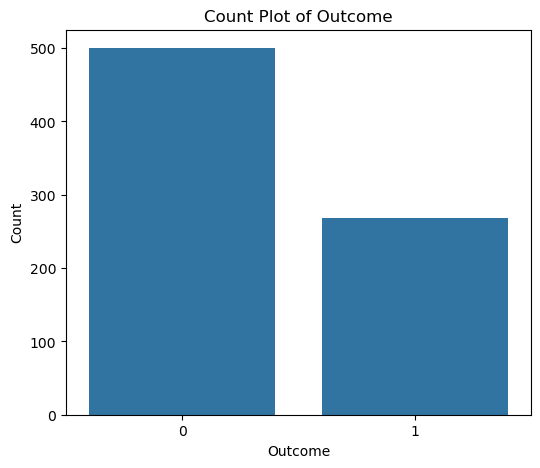

In [21]:
plt.figure(figsize=(6, 5))

sns.countplot(data=df, x="Outcome")

plt.title("Count Plot of Outcome")
plt.xlabel("Outcome")
plt.ylabel("Count")

plt.show()

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Glucose",
    y="BMI",
    hue="Outcome"
)

plt.title("Scatter Plot: Glucose vs BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")

plt.show()

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
sns.pairplot(
    df,
    hue="Outcome"
)

plt.show()

In [11]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_count = (df[zero_columns] == 0).sum()

print(zero_count)

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [13]:
df_clean = df.copy()

df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)

print("missing values after replacing invalid zeroes")
print(df_clean.isnull().sum())

missing values after replacing invalid zeroes
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [15]:
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("MISSING VALUES AFTER MEDIAN IMPUTATION")
print(df_clean.isnull().sum())

MISSING VALUES AFTER MEDIAN IMPUTATION
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [16]:
X = df_clean.drop("Outcome",axis=1)
y = df_clean["Outcome"]

print("X shape: ",X.shape)
print("y shape: ",y.shape)

X shape:  (768, 8)
y shape:  (768,)


In [17]:
X_train, X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training samples: ",X_train.shape[0])
print("Testing samples: ",X_test.shape[0])

Training samples:  614
Testing samples:  154


In [18]:
print("Training Distribution: ")
print(y_train.value_counts(normalize=True))

print("Testing Distribution: ")
print(y_test.value_counts(normalize=True))

Training Distribution: 
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Testing Distribution: 
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [26]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [27]:
comparison = pd.DataFrame({
    "Original Mean" : X_train.mean(),
    "Original Std": X_train.std(),
    "Scaled Mean" : X_train_scaled.mean(axis=0),
    "Scaled Std" : X_train_scaled.std(axis=0)
})

In [28]:
K = 5
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled,y_train)

KNeighborsClassifier()

In [ ]:
y_pred = knn.predict(

In [ ]:
accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy: {accuracy:.4f}")

In [ ]:
precision = precision_score(y_test,y_pred)
print(f"precision: {precision:.4f}")

In [ ]:
recall = recall_score(y_test,y_pred)
print(f"recall: {recall:.4f}")

In [ ]:
f1 = f1_score(y_test,y_pred)
print(f"f1: {f1:.4f}")

In [ ]:
print(classification_report(y_test,y_pred,target_names=["No Diabetes","Diabetes"]))

In [ ]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

In [ ]:
plt.figure(figsize=(7,6))

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["No Diabetes","Diabetes"],
            yticklabels

In [ ]:
k_values = range(1,31)

train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled,y_train)
    train_accuracy.append(model.score(X_train_scaled,y_train))
    test_accuracy.append(model.score(X_test_scaled,y_test))

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(k_values,train_accuracy,marker="o",label="Training Accuracy")
plt.plot(k_values,test_accuracy,marker="o",label="Testing Accuracy")

plt.show()

In [ ]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]

best_accuracy = max(test_accuracy)

print("Best k : ",best_k_accuracy)
print("Beat Test : ",best_accuracy)

In [ ]:
cv = StratifiedKFold(n_split=5,shuffle=True,random_state=42)

cv_scores= []

for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model,X_train_scaled,y_train,cv=cv,scoring="accuracy")
    cv_scores.append(scores.mean)

In [ ]:
best_k_cv = np.argmax(cv_scores)+1

print("Best k based on cross validation: ",best_k_cv)
print("Best CV accuracy: ",max(cv_scores))

In [ ]:
param_grid = {"n_neighbors":list(range(3,31,2)),"weights":["uniform","distance"],
             "metric":["euclidean","manhattan","minkowski"],
             "p":[1,2]
             }

In [ ]:
grid_search = GridSearchCV(estimator=KNeighborsClassifier(),param_grid=param_grid,cv=5,
                           scoring="accuracy",n_jobs=-1)

grid_search.fit(X_train_scaled,y_train)

print("Grid Search completed.")

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

In [ ]:
print("Best Cross-validation Accuracy: ",grid_search.best_score_)

In [ ]:
best_knn = grid_search.best_estimator_
print(best_knn)

In [ ]:
final